<h1 style="color:red; text-align:center">Practical: Data Analysis & Vectors</h1>

<span style="color:#c00">Instructor: Dr. Khaled Mohamad</span>

---
## Q1. Distance Matrix with NumPy Broadcasting

You have **3 delivery locations** (group A) and **2 warehouses** (group B), given as 2D coordinates:

```python
A = np.array([[1, 2],
              [4, 6],
              [7, 1]])

B = np.array([[0, 0],
              [5, 5]])
```

1. Reshape `A` and `B` for broadcasting: `A_exp = A[:, np.newaxis, :]` and `B_exp = B[np.newaxis, :, :]`. Print both shapes.
2. Compute the difference `diff = A_exp - B_exp`. Print its shape.
3. Compute the **Euclidean distance matrix** using `np.sqrt(np.sum(diff**2, axis=2))`. Print the result rounded to 2 decimal places.
4. In a Markdown cell, answer: which warehouse (B0 or B1) is **closer on average** to all delivery locations?

### ANSWER

In [37]:
import numpy as np

A = np.array([[1, 2], [4, 6], [7, 1]])
B = np.array([[0, 0], [5, 5]])

In [39]:
# 1) reshape for broadcasting
A_exp = A[:, np.newaxis, :] 
B_exp = B[np.newaxis, :, :] 

print("A_exp shape:", A_exp.shape)
print("B_exp shape:", B_exp.shape)

A_exp shape: (3, 1, 2)
B_exp shape: (1, 2, 2)


In [41]:
#2) difference
diff = A_exp - B_exp 
print("Diff shape:", diff.shape)

Diff shape: (3, 2, 2)


In [43]:
#3) distance matrix
distance_matrix = np.sqrt(np.sum(diff**2, axis=2))

distance_matrix_rounded = np.round(distance_matrix, 2)

print("distance matrix:")
print(distance_matrix_rounded)

distance matrix:
[[2.24 5.  ]
 [7.21 1.41]
 [7.07 4.47]]


In [45]:
#4) average distance per warehouse
average_distances = np.mean(distance_matrix, axis=0)
print("B0 average distance:", round(average_distances[0], 2))
print("B1 average distance:", round(average_distances[1], 2))

B0 average distance: 5.51
B1 average distance: 3.63


**Answer Q1.4:** 
Warehouse B1 is closer on average to all delivery locations (3.63 vs 5.51).


---
## Q2. Given:

```
p = [2, 1, -3]
q = [4, -2, 1]
```

1. Compute `p · q` using four different methods (loop, `np.dot`, `np.multiply + sum`, `np.matmul`).
2. Using the **geometric formula** `p · q = ||p|| × ||q|| × cos(θ)`, compute the angle θ between `p` and `q` in **both radians and degrees**.
3. Interpret the angle: are the vectors more aligned, perpendicular, or opposing?
4. Now create a vector `r` that is **guaranteed to be orthogonal to** `p` (dot product = 0) in 3D. Verify it numerically.

### ANSWER

In [49]:
import numpy as np

p_arr = np.array([2, 1, -3])
q_arr = np.array([4, -2, 1])

In [51]:
# 1) four methods

# Loop
dot_loop = sum(p_arr[i] * q_arr[i] for i in range(len(p_arr)))

# np.dot()
dot_np_dot = np.dot(p_arr, q_arr)

# np.multiply() + sum()
dot_multiply_sum = np.sum(np.multiply(p_arr, q_arr))

# np.matmul()
dot_matmul = np.matmul(p_arr, q_arr)

print("1) Loop:", dot_loop)
print("2) np.dot():", dot_np_dot)
print("3) np.multiply + sum:", dot_multiply_sum)
print("4) np.matmul():", dot_matmul)

1) Loop: 3
2) np.dot(): 3
3) np.multiply + sum: 3
4) np.matmul(): 3


In [53]:
# 2) angle
dot_prod = np.dot(p_arr, q_arr)
norm_p = np.linalg.norm(p_arr)
norm_q = np.linalg.norm(q_arr)

cos_theta = dot_prod / (norm_p * norm_q)
cos_theta = np.clip(cos_theta, -1.0, 1.0)

angle_rad = np.arccos(cos_theta)
angle_deg = np.degrees(angle_rad)

print(f"Angle in radians: {angle_rad:.4f}")
print(f"Angle in degrees: {angle_deg:.2f}°")

Angle in radians: 1.3949
Angle in degrees: 79.92°


In [55]:
# 3) interpretation
print("The vectors are nearly orthogonal / slightly opposing, as the angle is close to 90 degrees")

The vectors are nearly orthogonal / slightly opposing, as the angle is close to 90 degrees


In [57]:
# 4) construct orthogonal vector

r = np.cross(p_arr, [0, 0, 1])

if np.all(r == 0):
    r = np.cross(p_arr, [0, 1, 0])

print("Constructed vector r:", r)
print("Verification (scalar product of p and r):", np.dot(p_arr, r))

Constructed vector r: [ 1 -2  0]
Verification (scalar product of p and r): 0


---
## Q3. Given vectors:

```
u = [3, -4]
v = [-6, 8]
```

1. Compute the magnitudes of `u` and `v`. What is the ratio `||v|| / ||u||`? What does this ratio tell you?
2. Compute the unit vectors of `u` and `v`. What do you notice?
3. Are `u` and `v` parallel? Justify your answer mathematically (do **not** just plot — use the dot product and magnitudes).
4. On a single plot, draw `u`, `v`, and the unit vector of `u`. Add a legend and dashed axes.

### ANSWER

In [60]:
import numpy as np

u = np.array([3, -4])
v = np.array([-6, 8])

In [62]:
# 1) magnitudes and ratio
norm_u = np.linalg.norm(u)
norm_v = np.linalg.norm(v)

# 2 ||v|| / ||u||
ratio = norm_v / norm_u

print(f"Length of ||u||: {norm_u}")
print(f"Length of ||v||: {norm_v}")
print(f"ratio: {ratio}")

Length of ||u||: 5.0
Length of ||v||: 10.0
ratio: 2.0


In [64]:
# 2) unit vectors
unit_u = u / norm_u
unit_v = v / norm_v

print("Unit vector u:", unit_u)
print("Unit vector v:", unit_v)

Unit vector u: [ 0.6 -0.8]
Unit vector v: [-0.6  0.8]


In [66]:
# 3) parallel check using dot product
dot_uv = np.dot(u, v)

is_parallel = np.isclose(abs(dot_uv), norm_u * norm_v)

print(f"dot_uv: {dot_uv}")
print(f"is_parallel: {is_parallel}")

dot_uv: -50
is_parallel: True


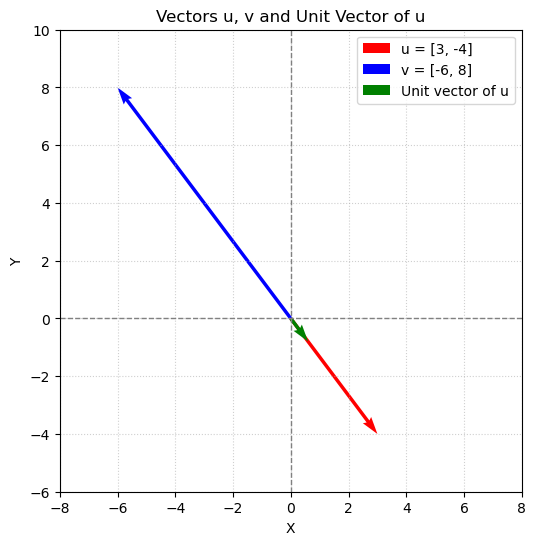

In [68]:
# 4) Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color='r', label='u = [3, -4]')
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='b', label='v = [-6, 8]')
plt.quiver(0, 0, unit_u[0], unit_u[1], angles='xy', scale_units='xy', scale=1, color='g', label='Unit vector of u')

plt.xlim(-8, 8)
plt.ylim(-6, 10)

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(0, color='grey', linestyle='--', linewidth=1)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.title("Vectors u, v and Unit Vector of u")
plt.xlabel("X")
plt.ylabel("Y")
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

---
## Q4. Pandas: Load, Explore & Clean

Load the **MPG** dataset (car fuel efficiency), a dataset built into Seaborn:

```python
df = sns.load_dataset('mpg')
```
Each row is a car model. Key columns: `mpg` (miles per gallon), `cylinders`, `weight`, `horsepower`, `origin`, `name`.

1. Print the **shape** and display the **first 5 rows**.
2. Print the **number of missing values per column**. Which column has missing values?
3. Create `df_clean` by **dropping rows** with any missing values using `.dropna()`. Print the new shape.
4. Print basic **summary statistics** using `.describe()`. What is the average `mpg`?

### ANSWER

In [71]:
# load the dataset
import pandas as pd
import seaborn as sns

df = sns.load_dataset('mpg')
print("Dataset loaded!")

Dataset loaded!


In [155]:
# 1)
print("Dataset size (rows, columns):", df.shape)
display(df.head())

Dataset size (rows, columns): (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [157]:
#2)
missing_values = df.isnull().sum()
print(missing_values)

cols_with_missing = missing_values[missing_values > 0]
print(list(cols_with_missing.index))

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
['horsepower']


In [159]:
# 3)
df_clean = df.dropna()

print("New dataset size:", df_clean.shape)

New dataset size: (392, 9)


In [161]:
# 4)
summary_stats = df_clean.describe()
display(summary_stats)

mean_mpg = df_clean['mpg'].mean()
print(f"Average mpg value: {mean_mpg:.2f}")

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


Average mpg value: 23.45


**Your answers:**
* **Missing values column:** horsepower
* **New shape after dropping missing values:** (392, 9)
* **Average mpg value:** 23.45

---
## Q5. Filtering, Sorting & GroupBy

Using `df_clean` from Q2:

1. **Filter** cars with `mpg > 30` (fuel-efficient cars). Print how many there are.
2. **Sort** the dataset by `mpg` in **descending order** and display the **top 5** most fuel-efficient cars — show only the columns `name`, `mpg`, `cylinders`, `origin`.
3. Use **GroupBy** to find the **average mpg per country of origin** (`origin`). Print the result.
4. In one Markdown sentence, state which country produces the most fuel-efficient cars on average.

### ANSWER

In [165]:
# 1)
efficient_cars = df_clean[df_clean['mpg'] > 30]

print(len(efficient_cars))

83


In [167]:
# 2)
top_fuel_efficient = df_clean.sort_values(by='mpg', ascending=False)[['name', 'mpg', 'cylinders', 'origin']].head(5)

display(top_fuel_efficient)

,name,mpg,cylinders,origin
322,mazda glc,46.6,4,japan
329,honda civic 1500 gl,44.6,4,japan
325,vw rabbit c (diesel),44.3,4,europe
394,vw pickup,44.0,4,europe
326,vw dasher (diesel),43.4,4,europe


In [169]:
# 3)
avg_mpg_by_origin = df_clean.groupby('origin')['mpg'].mean()

print(avg_mpg_by_origin)

origin
europe    27.602941
japan     30.450633
usa       20.033469
Name: mpg, dtype: float64


**Answer Q3.4: On average, cars originating from Japan (japan) are the most fuel-efficient.** ...

---
## Q6. Visualization

Using `df_clean`, create a figure with **two subplots side by side** (`figsize=(12, 4)`):

- **Left subplot:** A **bar plot** of average `mpg` per `origin`. Title: `'Average MPG by Country'`. Add a y-axis label `'MPG'`.
- **Right subplot:** A **scatter plot** of `weight` (x-axis) vs `mpg` (y-axis). Title: `'MPG vs Car Weight'`. Add axis labels.

Use `plt.tight_layout()` and `plt.show()`. In a Markdown cell, write **one observation** from the scatter plot.

### ANSWER

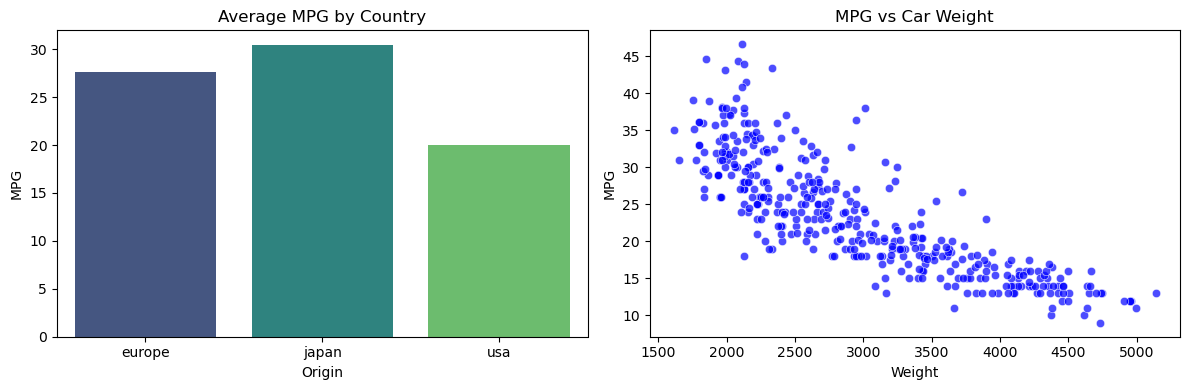

In [173]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

avg_mpg = df_clean.groupby('origin')['mpg'].mean().reset_index()
sns.barplot(data=avg_mpg, x='origin', y='mpg', ax=axes[0], palette='viridis')
axes[0].set_title('Average MPG by Country')
axes[0].set_ylabel('MPG')
axes[0].set_xlabel('Origin')

sns.scatterplot(data=df_clean, x='weight', y='mpg', ax=axes[1], color='b', alpha=0.7)
axes[1].set_title('MPG vs Car Weight')
axes[1].set_xlabel('Weight')
axes[1].set_ylabel('MPG')

plt.tight_layout()
plt.show()

**Observation: There is a strong negative correlation between car weight and MPG — as the weight of the car increases, the fuel efficiency (MPG) decreases.**

---
## Q7. KNN Classification on the Wine Dataset

The **Wine dataset** contains chemical measurements of wines from 3 different cultivars (classes 0, 1, 2). It is loaded from sklearn.

1. Load the dataset and print `feature_names`, `target_names`, and the shape of the data.
2. Split into **train/test sets** (75% train, 25% test) using `random_state=42`.
3. Train a `KNeighborsClassifier` with `n_neighbors=5`. Print the **test accuracy**.
4. In a Markdown cell, state in one sentence whether this is a **classification** or **regression** problem and why.

### ANSWER

In [177]:
from sklearn.datasets import load_wine
# 1) load
wine = load_wine()

print("Feature names:", wine.feature_names)
print("Target names:", wine.target_names)
print("Dataset shape:", wine.data.shape)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target names: ['class_0' 'class_1' 'class_2']
Dataset shape: (178, 13)


In [179]:
# 2) split
from sklearn.model_selection import train_test_split

X = wine.data
y = wine.target

X_train, X_test, y_train, X_test_labels = train_test_split(X, y, test_size=0.25, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (133, 13)
X_test shape: (45, 13)


In [181]:
# 3) train and evaluate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy = accuracy_score(X_test_labels, y_pred)
print(f"Test accuracy: {accuracy:.4f}")

Test accuracy: 0.7111


**Answer Q7.4: This is a classification problem because the target variable consists of discrete categorical classes (wine cultivars 0, 1, and 2) rather than continuous numerical values.**